In [158]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import IsolationForest
import ast
import time
import warnings
warnings.filterwarnings('ignore')

In [159]:
df = pd.read_csv('data/borg_traces_data.csv')

In [160]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)


Dataset shape: (405894, 34)

Data types:
Unnamed: 0                           int64
time                                 int64
instance_events_type                 int64
collection_id                        int64
scheduling_class                     int64
collection_type                      int64
priority                             int64
alloc_collection_id                  int64
instance_index                       int64
machine_id                           int64
resource_request                       str
constraint                             str
collections_events_type              int64
user                                   str
collection_name                        str
collection_logical_name                str
start_after_collection_ids             str
vertical_scaling                   float64
scheduler                          float64
start_time                           int64
end_time                             int64
average_usage                          str
maximum_usage

In [161]:
#convert string representation of list to actual list
def extract_cpu_usage(usage_str):
    try:
        usage_list = ast.literal_eval(usage_str)
        return usage_list.get('cpus', usage_list.get('cpu', None))
    except (ValueError, SyntaxError):
        return None
    
df['cpu_usage'] = df['average_usage'].apply(extract_cpu_usage)

In [162]:
# Normalize time values relative to the minimum, then add to target start date
max_time = 31 * 24 * 60 * 60 * 1000000  # 31 days in microseconds
df = df[df['time'] <= max_time].copy()

df = df[df['time'] != 0].copy()

target_start = pd.Timestamp('2019-05-01 00:00:00')

# Get relative time in microseconds from the minimum
relative_time_us = df['time'] - df['time'].min()

# Convert to timedelta and add to target start
df['timestamp'] = target_start + pd.to_timedelta(relative_time_us, unit='us')

print(df['timestamp'])

1        2019-05-30 03:05:03.177339
2        2019-05-03 06:11:21.892069
4        2019-05-21 22:47:05.363328
5        2019-05-19 19:42:22.366350
6        2019-05-02 12:08:39.239330
                    ...            
405888   2019-05-05 16:54:12.702072
405890   2019-05-01 04:54:37.036195
405891   2019-05-09 11:31:45.510705
405892   2019-05-23 23:05:20.998394
405893   2019-05-18 02:26:15.194036
Name: timestamp, Length: 349413, dtype: datetime64[us]


In [163]:
df_clean = df[df['cpu_usage'].notna()].copy()

hourly = df_clean.groupby(df_clean['timestamp'].dt.floor('h')).agg({
    'cpu_usage': 'mean'  # Average CPU across all tasks in that hour
}).reset_index()

hourly.columns = ['timestamp', 'cpu_usage']

hourly = hourly.sort_values('timestamp').reset_index(drop=True)

print(hourly)

              timestamp  cpu_usage
0   2019-05-01 00:00:00   0.008744
1   2019-05-01 01:00:00   0.007436
2   2019-05-01 02:00:00   0.007491
3   2019-05-01 03:00:00   0.010676
4   2019-05-01 04:00:00   0.009633
..                  ...        ...
739 2019-05-31 19:00:00   0.008983
740 2019-05-31 20:00:00   0.005455
741 2019-05-31 21:00:00   0.005123
742 2019-05-31 22:00:00   0.020139
743 2019-05-31 23:00:00   0.006876

[744 rows x 2 columns]


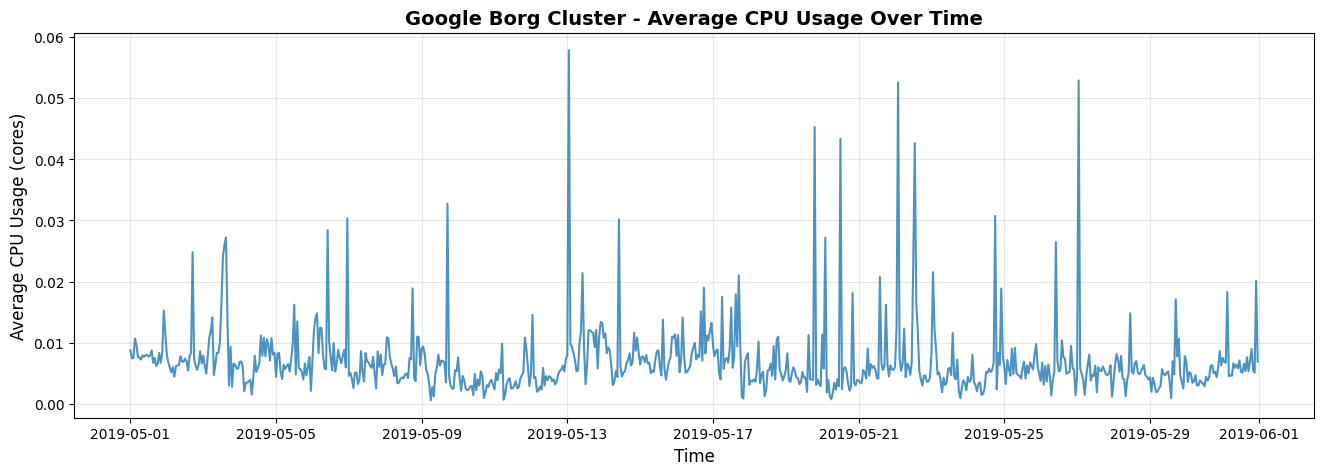

In [164]:
plt.figure(figsize=(16, 5))
plt.plot(hourly['timestamp'], hourly['cpu_usage'], linewidth=1.5, alpha=0.8)
plt.title('Google Borg Cluster - Average CPU Usage Over Time', 
          fontsize=14, fontweight='bold')
plt.xlabel('Time', fontsize=12)
plt.ylabel('Average CPU Usage (cores)', fontsize=12)
plt.grid(alpha=0.3)
plt.show()

In [165]:
train_size = int(len(hourly) * 0.8)
train, test = hourly[:train_size].copy(), hourly[train_size:].copy()

# Baseline Testing

In [166]:
# Baseline model: naive forecast (previous value)

last_value = train['cpu_usage'].iloc[-1]

baseline_predictions = np.full(len(test), last_value)

baseline_mae = mean_absolute_error(test['cpu_usage'], baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(test['cpu_usage'], baseline_predictions))

baseline_mape = np.mean(np.abs((test['cpu_usage'] - baseline_predictions) / test['cpu_usage'])) * 100

print("\n" + "="*60)
print("BASELINE PERFORMANCE")
print("="*60)
print(f"Mean Absolute Error (MAE):      {baseline_mae:.6f} cores")
print(f"Root Mean Squared Error (RMSE): {baseline_rmse:.6f} cores")
print(f"Mean Absolute % Error (MAPE):   {baseline_mape:.2f}%")
print("="*60)

print(f"\n📊 Interpretation:")
print(f"The baseline is off by an average of {baseline_mae:.4f} CPU cores")
print(f"Or approximately {baseline_mape:.1f}% error")
print(f"\n✅ This is our benchmark to beat!")


BASELINE PERFORMANCE
Mean Absolute Error (MAE):      0.002349 cores
Root Mean Squared Error (RMSE): 0.005016 cores
Mean Absolute % Error (MAPE):   52.96%

📊 Interpretation:
The baseline is off by an average of 0.0023 CPU cores
Or approximately 53.0% error

✅ This is our benchmark to beat!


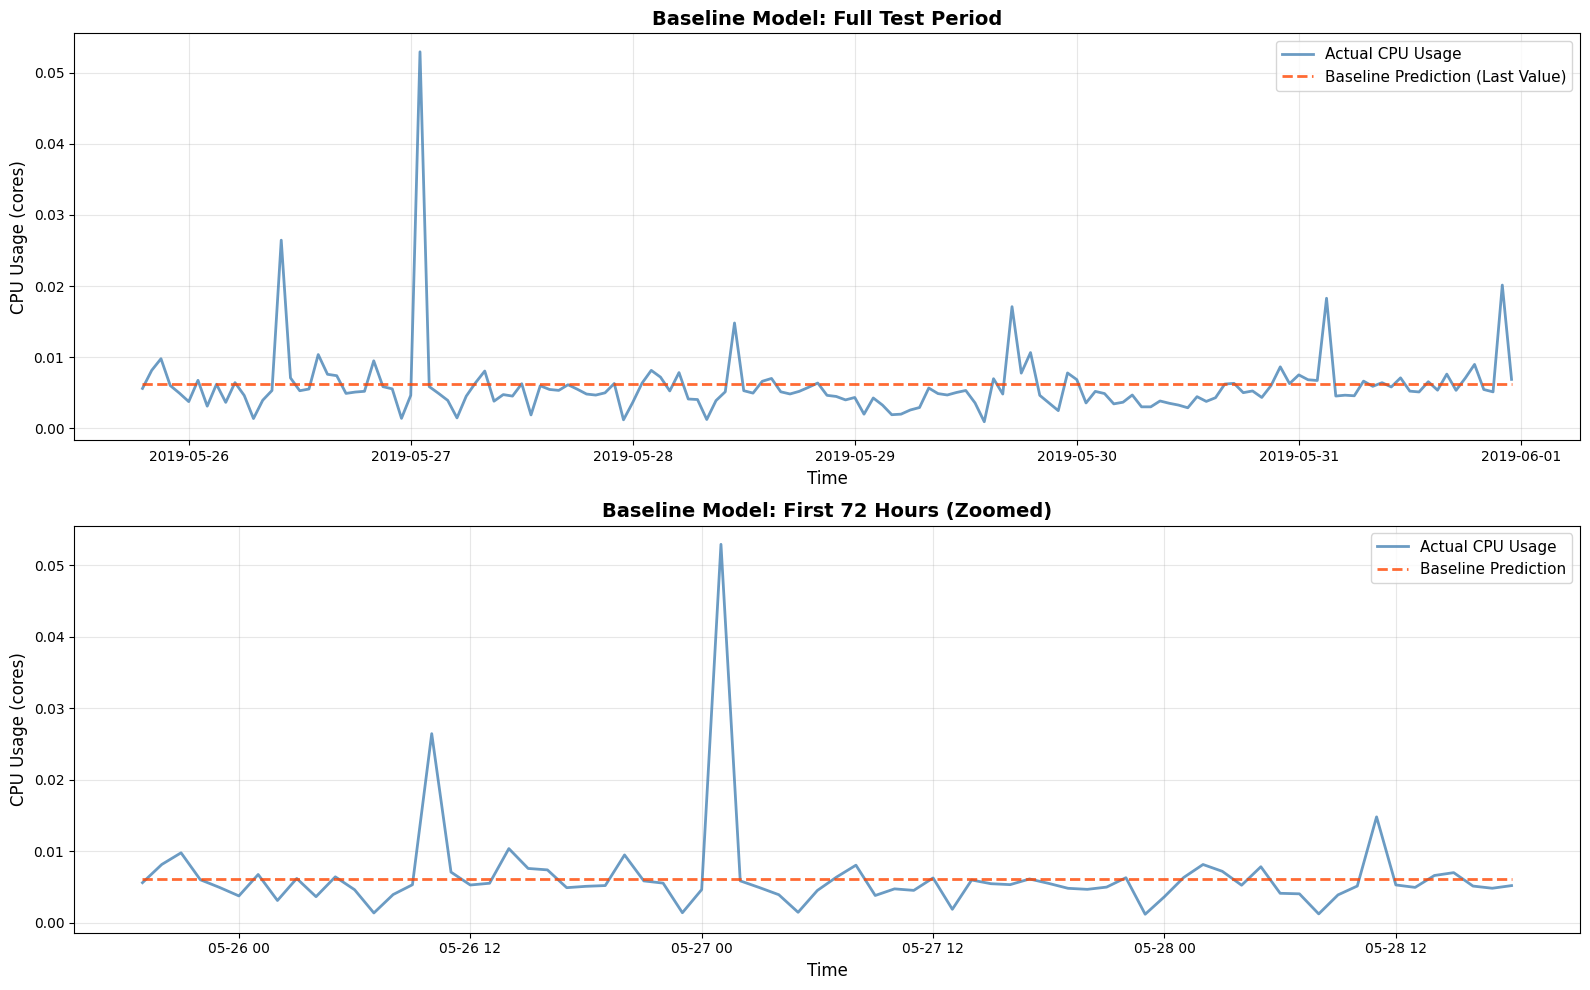

✅ Visualization saved as 'baseline_predictions.png'


In [167]:
# baseline visualization
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Full test period
axes[0].plot(test['timestamp'], test['cpu_usage'], 
            label='Actual CPU Usage', linewidth=2, alpha=0.8, color='steelblue')
axes[0].plot(test['timestamp'], baseline_predictions, 
            label='Baseline Prediction (Last Value)', linewidth=2, 
            linestyle='--', color='orangered', alpha=0.8)
axes[0].set_title('Baseline Model: Full Test Period', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Time', fontsize=12)
axes[0].set_ylabel('CPU Usage (cores)', fontsize=12)
axes[0].legend(fontsize=11, loc='upper right')
axes[0].grid(alpha=0.3)

# Zoom into first 3 days
first_72_hours = min(72, len(test))
axes[1].plot(test['timestamp'][:first_72_hours], test['cpu_usage'][:first_72_hours], 
            label='Actual CPU Usage', linewidth=2, alpha=0.8, color='steelblue')
axes[1].plot(test['timestamp'][:first_72_hours], baseline_predictions[:first_72_hours], 
            label='Baseline Prediction', linewidth=2, 
            linestyle='--', color='orangered', alpha=0.8)
axes[1].set_title('Baseline Model: First 72 Hours (Zoomed)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Time', fontsize=12)
axes[1].set_ylabel('CPU Usage (cores)', fontsize=12)
axes[1].legend(fontsize=11, loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('baseline_predictions.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Visualization saved as 'baseline_predictions.png'")

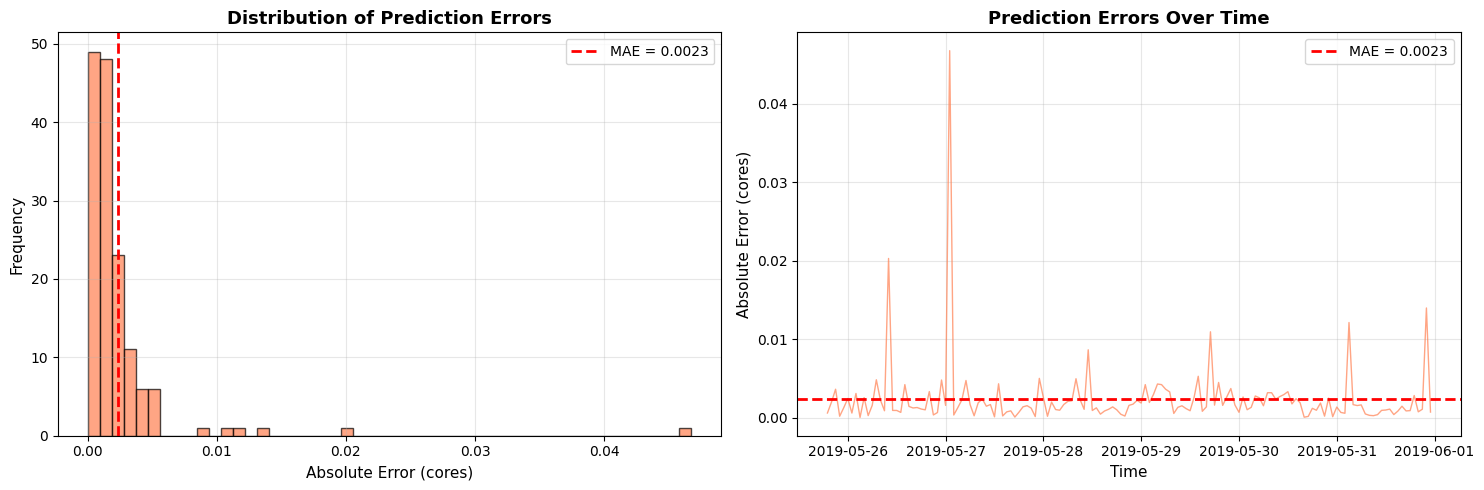


📊 Error Statistics:
Min error:  0.000016
Max error:  0.046751
Mean error: 0.002349 (MAE)
Median error: 0.001439
Std dev:    0.004432


In [168]:
# Calculate absolute errors
errors = np.abs(test['cpu_usage'].values - baseline_predictions)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Error distribution
axes[0].hist(errors, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0].axvline(baseline_mae, color='red', linestyle='--', linewidth=2, 
               label=f'MAE = {baseline_mae:.4f}')
axes[0].set_title('Distribution of Prediction Errors', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Absolute Error (cores)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# Error over time
axes[1].plot(test['timestamp'], errors, linewidth=1, alpha=0.7, color='coral')
axes[1].axhline(baseline_mae, color='red', linestyle='--', linewidth=2, 
               label=f'MAE = {baseline_mae:.4f}')
axes[1].set_title('Prediction Errors Over Time', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Time', fontsize=11)
axes[1].set_ylabel('Absolute Error (cores)', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n📊 Error Statistics:")
print(f"Min error:  {errors.min():.6f}")
print(f"Max error:  {errors.max():.6f}")
print(f"Mean error: {errors.mean():.6f} (MAE)")
print(f"Median error: {np.median(errors):.6f}")
print(f"Std dev:    {errors.std():.6f}")

In [169]:
baseline_results = {
    'model': 'Baseline (Naive)',
    'mae': baseline_mae,
    'rmse': baseline_rmse,
    'mape': baseline_mape,
    'predictions': baseline_predictions
}

# Prophet Testing

In [170]:
from prophet import Prophet

m = Prophet(
    daily_seasonality=True,
    yearly_seasonality=False,
    weekly_seasonality=True,
    changepoint_prior_scale=0.05
)

m.fit(train.rename(columns={'timestamp': 'ds', 'cpu_usage': 'y'}))

prophet_predictions = m.predict(test.rename(columns={'timestamp': 'ds'}))

prophet_predictions[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

prophet_mae = mean_absolute_error(test['cpu_usage'], prophet_predictions['yhat'])
prophet_rmse = np.sqrt(mean_squared_error(test['cpu_usage'], prophet_predictions['yhat']))
prophet_mape = np.mean(np.abs((test['cpu_usage'] - prophet_predictions['yhat']) / test['cpu_usage'])) * 100

prophet_improvement = ((baseline_mae - prophet_mae)/ baseline_mae) * 100

print(f"The prophet model achieved an MAE of {prophet_mae:.6f} cores, which is a {prophet_improvement:.2f}% improvement over the baseline.")

18:15:03 - cmdstanpy - INFO - Chain [1] start processing
18:15:03 - cmdstanpy - INFO - Chain [1] done processing


The prophet model achieved an MAE of 0.003150 cores, which is a -34.10% improvement over the baseline.


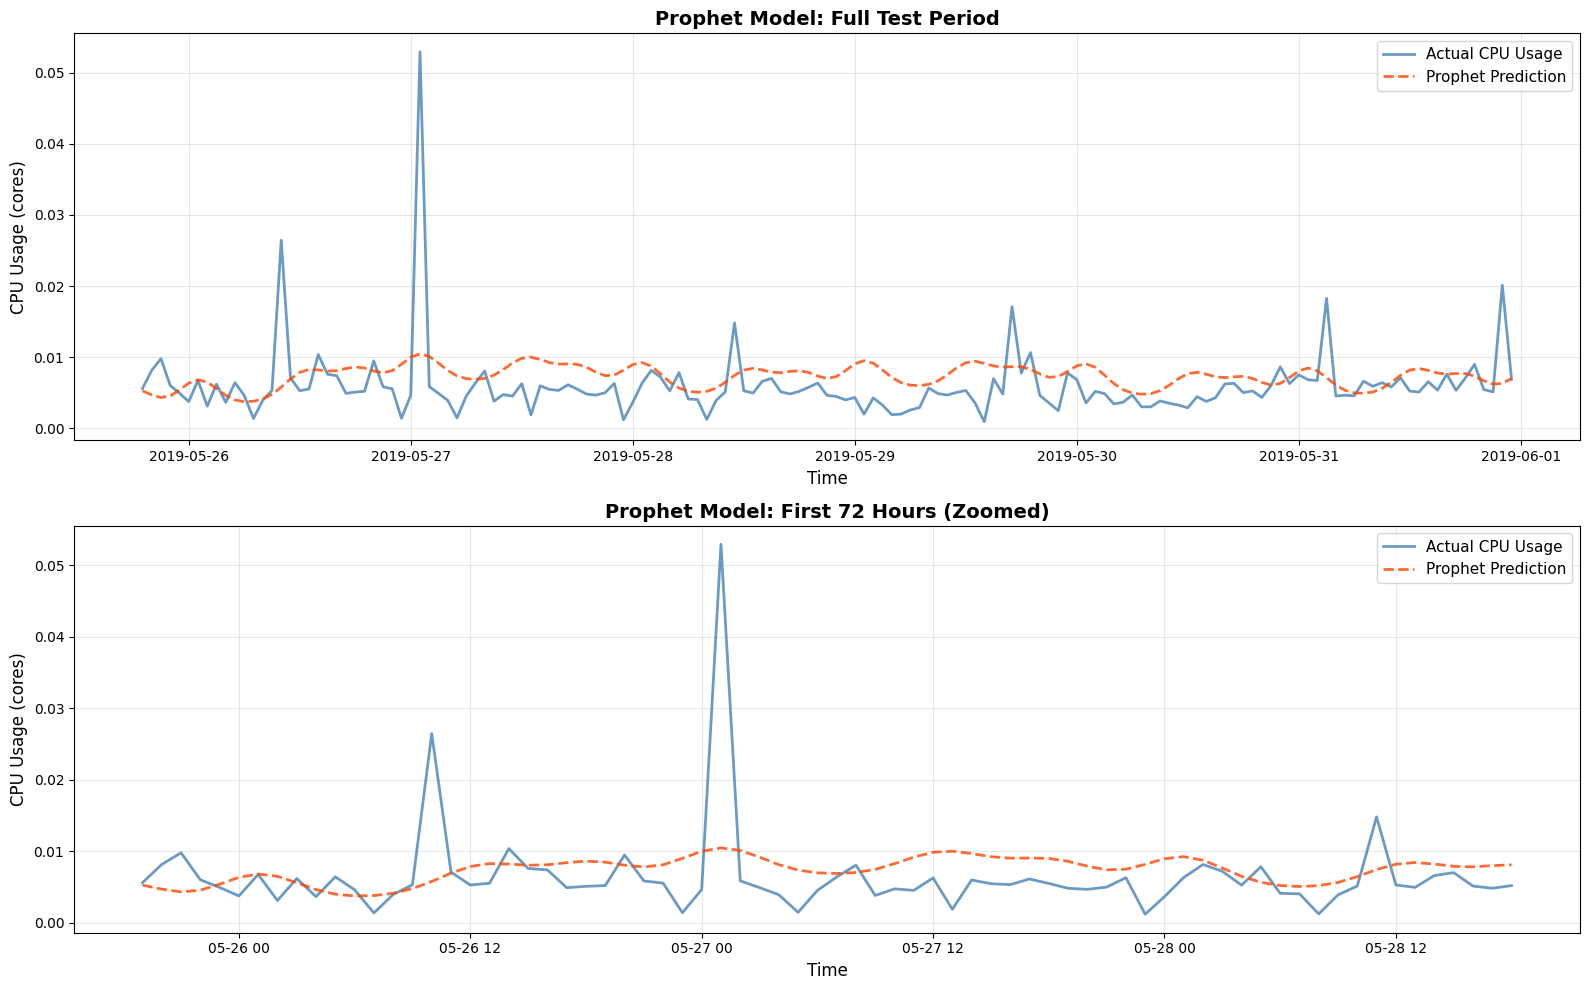

In [171]:
# prophet visualization
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Full test period
axes[0].plot(test['timestamp'], test['cpu_usage'], 
            label='Actual CPU Usage', linewidth=2, alpha=0.8, color='steelblue')
axes[0].plot(test['timestamp'], prophet_predictions['yhat'], 
            label='Prophet Prediction', linewidth=2, 
            linestyle='--', color='orangered', alpha=0.8)
axes[0].set_title('Prophet Model: Full Test Period', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Time', fontsize=12)
axes[0].set_ylabel('CPU Usage (cores)', fontsize=12)
axes[0].legend(fontsize=11, loc='upper right')
axes[0].grid(alpha=0.3)

first_72_hours = min(72, len(test))
axes[1].plot(test['timestamp'][:first_72_hours], test['cpu_usage'][:first_72_hours], 
            label='Actual CPU Usage', linewidth=2, alpha=0.8, color='steelblue')
axes[1].plot(test['timestamp'][:first_72_hours], prophet_predictions['yhat'][:first_72_hours], 
            label='Prophet Prediction', linewidth=2, 
            linestyle='--', color='orangered', alpha=0.8)
axes[1].set_title('Prophet Model: First 72 Hours (Zoomed)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Time', fontsize=12)
axes[1].set_ylabel('CPU Usage (cores)', fontsize=12)
axes[1].legend(fontsize=11, loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('prophet_predictions.png', dpi=300, bbox_inches='tight')
plt.show()


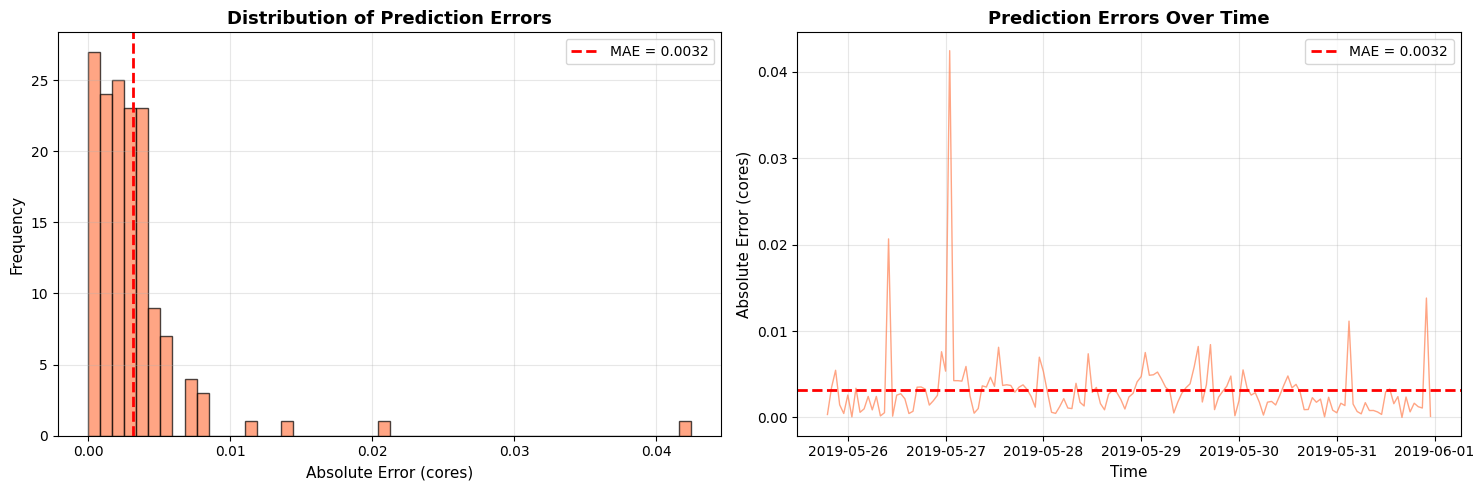


📊 Error Statistics:
Min error:  0.000005
Max error:  0.042468
Mean error: 0.003150 (MAE)
Median error: 0.002468
Std dev:    0.004152


In [172]:
# Calculate absolute errors
errors = np.abs(test['cpu_usage'].values - prophet_predictions['yhat'].values)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Error distribution
axes[0].hist(errors, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0].axvline(prophet_mae, color='red', linestyle='--', linewidth=2, 
               label=f'MAE = {prophet_mae:.4f}')
axes[0].set_title('Distribution of Prediction Errors', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Absolute Error (cores)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# Error over time
axes[1].plot(test['timestamp'], errors, linewidth=1, alpha=0.7, color='coral')
axes[1].axhline(prophet_mae, color='red', linestyle='--', linewidth=2, 
               label=f'MAE = {prophet_mae:.4f}')
axes[1].set_title('Prediction Errors Over Time', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Time', fontsize=11)
axes[1].set_ylabel('Absolute Error (cores)', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n📊 Error Statistics:")
print(f"Min error:  {errors.min():.6f}")
print(f"Max error:  {errors.max():.6f}")
print(f"Mean error: {errors.mean():.6f} (MAE)")
print(f"Median error: {np.median(errors):.6f}")
print(f"Std dev:    {errors.std():.6f}")

In [173]:
prophet_results = {
    'model': 'Prophet',
    'mae': prophet_mae,
    'rmse': prophet_rmse,
    'mape': prophet_mape,
    'predictions': prophet_predictions['yhat'].values
}

# Machine Learning

In [174]:
hourly['hour'] = hourly['timestamp'].dt.hour
hourly['day_of_week'] = hourly['timestamp'].dt.dayofweek

print("Time features created!")
print(f"\nSample of new columns:")
print(hourly[['timestamp', 'hour', 'day_of_week', 'cpu_usage']].head(10))


Time features created!

Sample of new columns:
            timestamp  hour  day_of_week  cpu_usage
0 2019-05-01 00:00:00     0            2   0.008744
1 2019-05-01 01:00:00     1            2   0.007436
2 2019-05-01 02:00:00     2            2   0.007491
3 2019-05-01 03:00:00     3            2   0.010676
4 2019-05-01 04:00:00     4            2   0.009633
5 2019-05-01 05:00:00     5            2   0.007666
6 2019-05-01 06:00:00     6            2   0.007579
7 2019-05-01 07:00:00     7            2   0.007239
8 2019-05-01 08:00:00     8            2   0.007927
9 2019-05-01 09:00:00     9            2   0.007680


In [175]:
hourly['lag_1'] = hourly['cpu_usage'].shift(1)
hourly['lag_24'] = hourly['cpu_usage'].shift(24)

print(f"\nSample with lag features:")
print(hourly[['timestamp', 'cpu_usage', 'lag_1', 'lag_24']].head(30))

# Check how many NaN values we created
print(f"\nNaN counts:")
print(f"lag_1: {hourly['lag_1'].isna().sum()} missing values")
print(f"lag_24: {hourly['lag_24'].isna().sum()} missing values")

hourly['rolling_mean_6'] = hourly['cpu_usage'].rolling(6).mean()
hourly['rolling_std_6'] = hourly['cpu_usage'].rolling(6).std()

hourly_clean = hourly.dropna()

# ============================================================
# STEP 4: VERIFY CLEAN DATA
# ============================================================

print("="*60)
print("DATA CLEANING RESULTS")
print("="*60)
print(f"Original rows: {len(hourly)}")
print(f"Clean rows: {len(hourly_clean)}")
print(f"Rows lost: {len(hourly) - len(hourly_clean)}")

print(hourly_clean.columns.tolist())

print(f"\nNo missing values:")
print(hourly_clean.isnull().sum())

print(f"\nSample of engineered data:")
print(hourly_clean[['timestamp', 'hour', 'day_of_week', 'lag_1', 'lag_24', 
                     'rolling_mean_6', 'rolling_std_6', 'cpu_usage']].head(10))


Sample with lag features:
             timestamp  cpu_usage     lag_1    lag_24
0  2019-05-01 00:00:00   0.008744       NaN       NaN
1  2019-05-01 01:00:00   0.007436  0.008744       NaN
2  2019-05-01 02:00:00   0.007491  0.007436       NaN
3  2019-05-01 03:00:00   0.010676  0.007491       NaN
4  2019-05-01 04:00:00   0.009633  0.010676       NaN
5  2019-05-01 05:00:00   0.007666  0.009633       NaN
6  2019-05-01 06:00:00   0.007579  0.007666       NaN
7  2019-05-01 07:00:00   0.007239  0.007579       NaN
8  2019-05-01 08:00:00   0.007927  0.007239       NaN
9  2019-05-01 09:00:00   0.007680  0.007927       NaN
10 2019-05-01 10:00:00   0.007971  0.007680       NaN
11 2019-05-01 11:00:00   0.007987  0.007971       NaN
12 2019-05-01 12:00:00   0.007724  0.007987       NaN
13 2019-05-01 13:00:00   0.007924  0.007724       NaN
14 2019-05-01 14:00:00   0.008755  0.007924       NaN
15 2019-05-01 15:00:00   0.006692  0.008755       NaN
16 2019-05-01 16:00:00   0.007505  0.006692       NaN
1

In [176]:
test_start_time = test['timestamp'].min()
# ============================================================
# STEP 5: TRAIN/TEST SPLIT (matching original split)
# ============================================================

# Find where our original test period started
test_start_time = test['timestamp'].min()

print(f"Test period starts at: {test_start_time}")

# Split engineered data at the same timestamp
train_rf = hourly_clean[hourly_clean['timestamp'] < test_start_time].copy()
test_rf = hourly_clean[hourly_clean['timestamp'] >= test_start_time].copy()

print(f"Training: {len(train_rf)} rows")
print(f"Test: {len(test_rf)} rows")


print(f"Original test had: {len(test)} rows")
print(f"RF test has: {len(test_rf)} rows")
print(f"Difference: {len(test) - len(test_rf)} rows")

print(f"Original test starts: {test['timestamp'].min()}")
print(f"RF test starts: {test_rf['timestamp'].min()}")
print(f"Match: {test['timestamp'].min() == test_rf['timestamp'].min()}")

Test period starts at: 2019-05-25 19:00:00
Training: 571 rows
Test: 149 rows
Original test had: 149 rows
RF test has: 149 rows
Difference: 0 rows
Original test starts: 2019-05-25 19:00:00
RF test starts: 2019-05-25 19:00:00
Match: True


In [177]:
feature_columns = ['hour', 'day_of_week', 'lag_1', 'lag_24', 
                   'rolling_mean_6', 'rolling_std_6']

# Training data
X_train = train_rf[feature_columns]
y_train = train_rf['cpu_usage']

# Test data
X_test = test_rf[feature_columns]
y_test = test_rf['cpu_usage']

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (571, 6)
y_train shape: (571,)
X_test shape: (149, 6)
y_test shape: (149,)


In [178]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

start_time = time.time()
rf_model.fit(X_train, y_train)
training_time = time.time() - start_time

print(f"Model trained in {training_time:.2f} seconds")
print(f"Number of trees: {rf_model.n_estimators}")
print(f"Number of features: {rf_model.n_features_in_}")

Model trained in 0.05 seconds
Number of trees: 100
Number of features: 6


In [179]:
rf_model_predictions = rf_model.predict(X_test)
rf_model_mae = mean_absolute_error(y_test, rf_model_predictions)
print(f"Random Forest MAE: {rf_model_mae:.6f} cores")
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_model_predictions))
rf_mape = np.mean(np.abs((y_test - rf_model_predictions) / y_test)) * 100

# Calculate improvement over baseline
rf_improvement = ((baseline_mae - rf_model_mae) / baseline_mae) * 100
print(f"Random Forest MAE: {rf_model_mae:.6f} cores, which is a {rf_improvement:.2f}% improvement over the baseline.")

random_forest_results = {
    'model': 'Random Forest',
    'mae': rf_model_mae,
    'rmse': rf_rmse,
    'mape': rf_mape,
    'predictions': rf_model_predictions
}

Random Forest MAE: 0.002398 cores
Random Forest MAE: 0.002398 cores, which is a -2.09% improvement over the baseline.


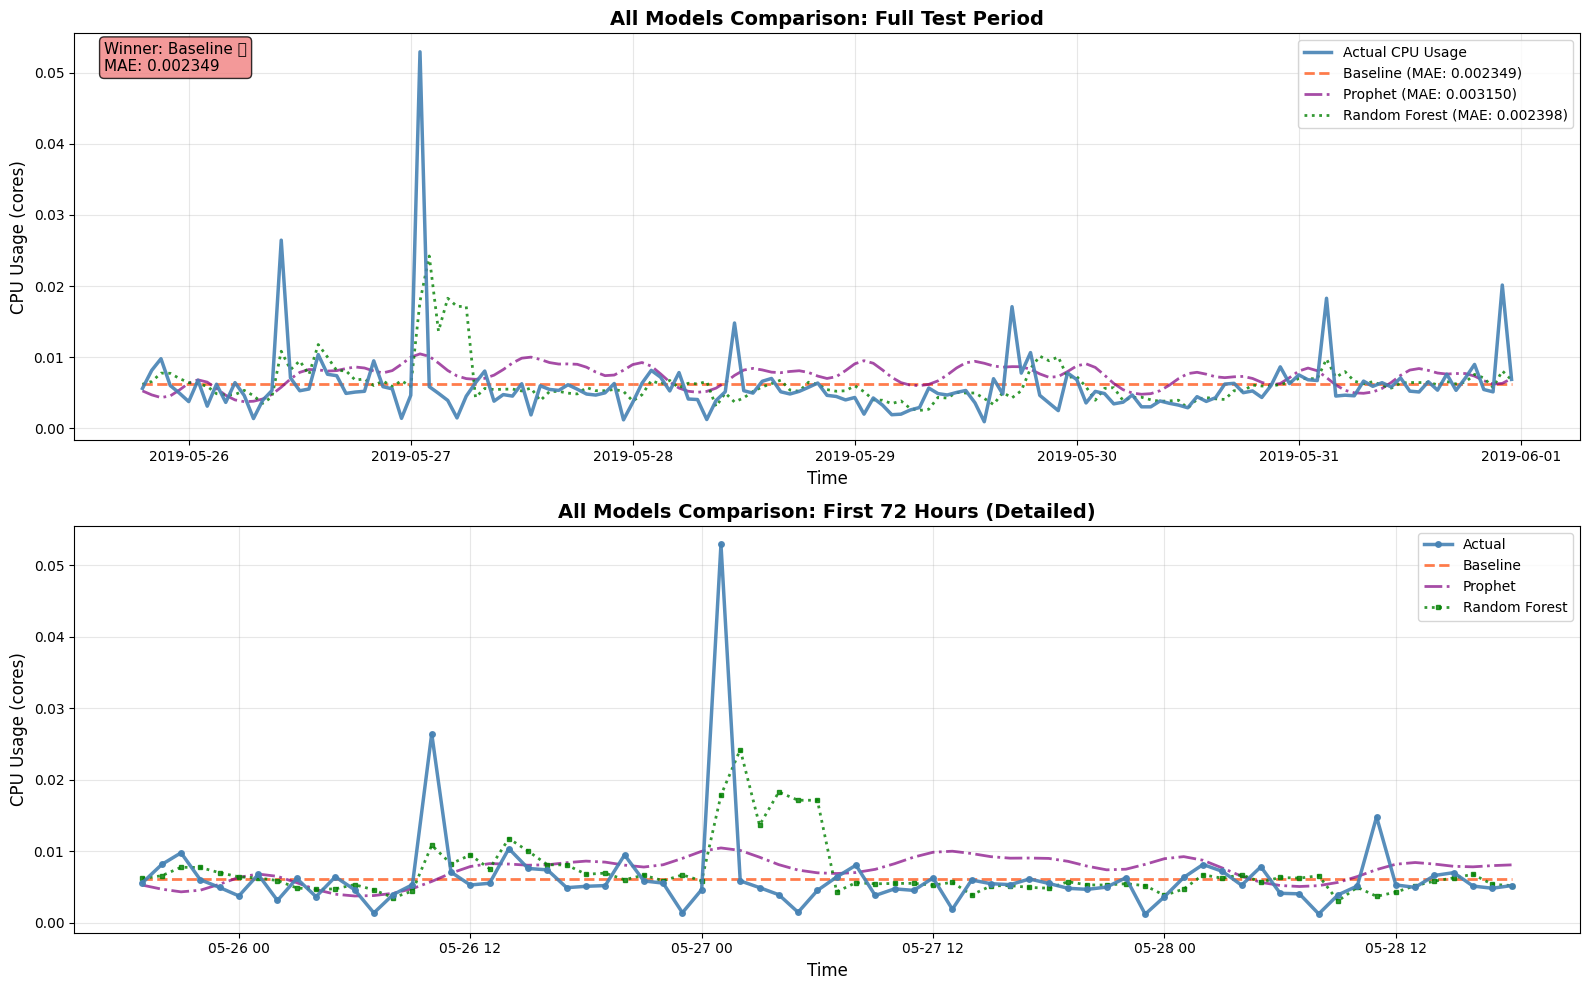

In [180]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Full test period - All three models
axes[0].plot(test_rf['timestamp'], y_test, 
            label='Actual CPU Usage', linewidth=2.5, alpha=0.9, 
            color='steelblue', zorder=4)
axes[0].plot(test_rf['timestamp'], baseline_predictions[:len(test_rf)], 
            label=f'Baseline (MAE: {baseline_mae:.6f})', linewidth=2, 
            linestyle='--', color='orangered', alpha=0.7, zorder=1)
axes[0].plot(test_rf['timestamp'], prophet_predictions['yhat'][:len(test_rf)], 
            label=f'Prophet (MAE: {prophet_mae:.6f})', linewidth=2, 
            linestyle='-.', color='purple', alpha=0.7, zorder=2)
axes[0].plot(test_rf['timestamp'], rf_model_predictions, 
            label=f'Random Forest (MAE: {rf_model_mae:.6f})', linewidth=2, 
            linestyle=':', color='green', alpha=0.8, zorder=3)

axes[0].set_title('All Models Comparison: Full Test Period', 
                  fontsize=14, fontweight='bold')
axes[0].set_xlabel('Time', fontsize=12)
axes[0].set_ylabel('CPU Usage (cores)', fontsize=12)
axes[0].legend(fontsize=10, loc='best')
axes[0].grid(alpha=0.3)

# Add winner box
winner = "Baseline"
textstr = f'Winner: {winner} ✅\nMAE: {baseline_mae:.6f}'
axes[0].text(0.02, 0.98, textstr, transform=axes[0].transAxes, 
            fontsize=11, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.8))

# Zoomed view: First 72 hours
hours_to_show = min(72, len(test_rf))
axes[1].plot(test_rf['timestamp'].iloc[:hours_to_show], 
            y_test.iloc[:hours_to_show], 
            label='Actual', linewidth=2.5, alpha=0.9, 
            color='steelblue', marker='o', markersize=4, zorder=4)
axes[1].plot(test_rf['timestamp'].iloc[:hours_to_show], 
            baseline_predictions[:hours_to_show], 
            label='Baseline', linewidth=2, linestyle='--', 
            color='orangered', alpha=0.7, zorder=1)
axes[1].plot(test_rf['timestamp'].iloc[:hours_to_show], 
            prophet_predictions['yhat'].iloc[:hours_to_show], 
            label='Prophet', linewidth=2, linestyle='-.', 
            color='purple', alpha=0.7, zorder=2)
axes[1].plot(test_rf['timestamp'].iloc[:hours_to_show], 
            rf_model_predictions[:hours_to_show], 
            label='Random Forest', linewidth=2, linestyle=':', 
            color='green', alpha=0.8, marker='s', markersize=3, zorder=3)

axes[1].set_title('All Models Comparison: First 72 Hours (Detailed)', 
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel('Time', fontsize=12)
axes[1].set_ylabel('CPU Usage (cores)', fontsize=12)
axes[1].legend(fontsize=10, loc='best')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('all_models_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

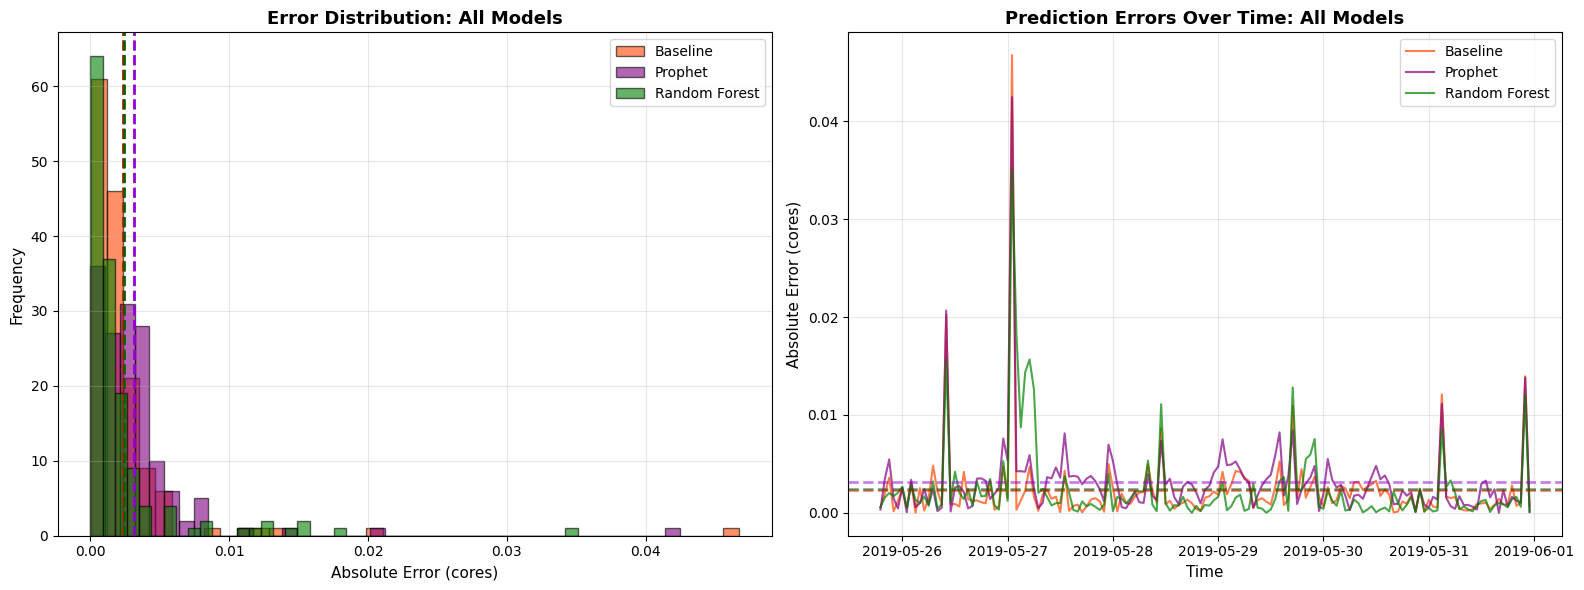

In [181]:
# ============================================================
# ERROR COMPARISON: ALL MODELS
# ============================================================

# Calculate errors for all models
baseline_errors = np.abs(y_test.values - baseline_predictions[:len(test_rf)])
prophet_errors = np.abs(y_test.values - prophet_predictions['yhat'].values[:len(test_rf)])
rf_errors = np.abs(y_test.values - rf_model_predictions)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Error distribution
axes[0].hist(baseline_errors, bins=40, edgecolor='black', alpha=0.6, 
            color='orangered', label='Baseline')
axes[0].hist(prophet_errors, bins=40, edgecolor='black', alpha=0.6, 
            color='purple', label='Prophet')
axes[0].hist(rf_errors, bins=40, edgecolor='black', alpha=0.6, 
            color='green', label='Random Forest')

axes[0].axvline(baseline_mae, color='red', linestyle='--', linewidth=2)
axes[0].axvline(prophet_mae, color='darkviolet', linestyle='--', linewidth=2)
axes[0].axvline(rf_model_mae, color='darkgreen', linestyle='--', linewidth=2)

axes[0].set_title('Error Distribution: All Models', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Absolute Error (cores)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# Errors over time
axes[1].plot(test_rf['timestamp'], baseline_errors, linewidth=1.5, 
            alpha=0.7, color='orangered', label='Baseline')
axes[1].plot(test_rf['timestamp'], prophet_errors, linewidth=1.5, 
            alpha=0.7, color='purple', label='Prophet')
axes[1].plot(test_rf['timestamp'], rf_errors, linewidth=1.5, 
            alpha=0.7, color='green', label='Random Forest')

axes[1].axhline(baseline_mae, color='red', linestyle='--', linewidth=2, alpha=0.5)
axes[1].axhline(prophet_mae, color='darkviolet', linestyle='--', linewidth=2, alpha=0.5)
axes[1].axhline(rf_model_mae, color='darkgreen', linestyle='--', linewidth=2, alpha=0.5)

axes[1].set_title('Prediction Errors Over Time: All Models', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Time', fontsize=11)
axes[1].set_ylabel('Absolute Error (cores)', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('all_models_error_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Detect Anomalies With Isolation Forest

In [182]:
iso_forest = IsolationForest(contamination=0.05, random_state=42, n_estimators=100)

start_time = time.time()
iso_forest.fit(X_train)
training_time = time.time() - start_time

print(f"Isolation Forest trained in {training_time:.2f} seconds")
print(f"Number of trees: {iso_forest.n_estimators}")
print(f"Expected anomalies: ~{int(len(X_test) * 0.05)} out of {len(X_test)} test hours")


Isolation Forest trained in 0.04 seconds
Number of trees: 100
Expected anomalies: ~7 out of 149 test hours


In [183]:
anomaly_predictions = iso_forest.predict(X_test)

is_normal = (anomaly_predictions == 1)
is_anomaly = (anomaly_predictions == -1)
print(f"Total test hours: {len(y_test)}")
print(f"Normal hours: {is_normal.sum()} ({is_normal.sum()/len(y_test)*100:.1f}%)")
print(f"Anomaly hours: {is_anomaly.sum()} ({is_anomaly.sum()/len(y_test)*100:.1f}%)")
print(f"\nDetected anomalies at:")
anomaly_timestamps = test_rf['timestamp'].iloc[is_anomaly].values
anomaly_cpu_values = y_test.iloc[is_anomaly].values

for timestamp, cpu in zip(anomaly_timestamps, anomaly_cpu_values):
    print(f"   {timestamp}: CPU = {cpu:.6f} cores")

Total test hours: 149
Normal hours: 145 (97.3%)
Anomaly hours: 4 (2.7%)

Detected anomalies at:
   2019-05-27T01:00:00.000000: CPU = 0.052931 cores
   2019-05-27T02:00:00.000000: CPU = 0.005859 cores
   2019-05-27T06:00:00.000000: CPU = 0.004518 cores
   2019-05-28T01:00:00.000000: CPU = 0.006337 cores


In [184]:
# ============================================================
# STEP 3: PERFORMANCE BREAKDOWN - NORMAL VS ANOMALY HOURS
# ============================================================

# Calculate MAE separately for normal hours
baseline_mae_normal = mean_absolute_error(
    y_test[is_normal], 
    baseline_predictions[:len(test_rf)][is_normal]
)

rf_mae_normal = mean_absolute_error(
    y_test[is_normal], 
    rf_model_predictions[is_normal]
)

prophet_mae_normal = mean_absolute_error(
    y_test[is_normal],
    prophet_predictions['yhat'].values[:len(test_rf)][is_normal]
)

# Calculate MAE separately for anomaly hours
baseline_mae_anomaly = mean_absolute_error(
    y_test[is_anomaly], 
    baseline_predictions[:len(test_rf)][is_anomaly]
)

rf_mae_anomaly = mean_absolute_error(
    y_test[is_anomaly], 
    rf_model_predictions[is_anomaly]
)

prophet_mae_anomaly = mean_absolute_error(
    y_test[is_anomaly],
    prophet_predictions['yhat'].values[:len(test_rf)][is_anomaly]
)

print("\n" + "="*60)
print("MAE BREAKDOWN: NORMAL VS ANOMALY HOURS")
print("="*60)

print(f"\nOn NORMAL hours ({is_normal.sum()} hours = {is_normal.sum()/len(y_test)*100:.1f}%):")
print(f"   Baseline:      {baseline_mae_normal:.6f}")
print(f"   Random Forest: {rf_mae_normal:.6f}")
print(f"   Prophet:       {prophet_mae_normal:.6f}")

if rf_mae_normal < baseline_mae_normal:
    improvement = ((baseline_mae_normal - rf_mae_normal)/baseline_mae_normal*100)
    print(f"\nRandom Forest BEATS baseline by {improvement:.2f}% on normal hours!")
else:
    worse = ((rf_mae_normal - baseline_mae_normal)/baseline_mae_normal*100)
    print(f"\nBaseline still wins by {worse:.2f}% on normal hours")

if prophet_mae_normal < baseline_mae_normal:
    improvement = ((baseline_mae_normal - prophet_mae_normal)/baseline_mae_normal*100)
    print(f"Prophet ALSO beats baseline by {improvement:.2f}% on normal hours!")

print(f"\nOn ANOMALY hours ({is_anomaly.sum()} hours = {is_anomaly.sum()/len(y_test)*100:.1f}%):")
print(f"   Baseline:      {baseline_mae_anomaly:.6f}")
print(f"   Random Forest: {rf_mae_anomaly:.6f}")
print(f"   Prophet:       {prophet_mae_anomaly:.6f}")
print(f"\n All models struggle with anomalies (expected)")

print(f"\nOverall (all hours):")
print(f"   Baseline: {baseline_mae:.6f}")
print(f"   RF:       {rf_model_mae:.6f} ({((rf_model_mae-baseline_mae)/baseline_mae*100):+.1f}%)")
print(f"   Prophet:  {prophet_mae:.6f} ({((prophet_mae-baseline_mae)/baseline_mae*100):+.1f}%)")

print(f"\nNormal hours only:")
print(f"   Baseline: {baseline_mae_normal:.6f}")
print(f"   RF:       {rf_mae_normal:.6f} ({((rf_mae_normal-baseline_mae_normal)/baseline_mae_normal*100):+.1f}%)")
print(f"   Prophet:  {prophet_mae_normal:.6f} ({((prophet_mae_normal-baseline_mae_normal)/baseline_mae_normal*100):+.1f}%)")

if rf_mae_normal < baseline_mae_normal:
    print("Random Forest performs better on normal hours!")
    print("Anomalies degraded its overall performance.")
    print("\nRecommendation: Use hybrid approach")
    print("   • Isolation Forest for anomaly detection")
    print("   • Random Forest for normal hour forecasting")
else:
    print("Baseline wins consistently across both normal and anomaly hours.")
    print("The data is genuinely stable - simplicity is best.")


MAE BREAKDOWN: NORMAL VS ANOMALY HOURS

On NORMAL hours (145 hours = 97.3%):
   Baseline:      0.002077
   Random Forest: 0.001998
   Prophet:       0.002878

Random Forest BEATS baseline by 3.82% on normal hours!

On ANOMALY hours (4 hours = 2.7%):
   Baseline:      0.012223
   Random Forest: 0.016924
   Prophet:       0.013026

 All models struggle with anomalies (expected)

Overall (all hours):
   Baseline: 0.002349
   RF:       0.002398 (+2.1%)
   Prophet:  0.003150 (+34.1%)

Normal hours only:
   Baseline: 0.002077
   RF:       0.001998 (-3.8%)
   Prophet:  0.002878 (+38.6%)
Random Forest performs better on normal hours!
Anomalies degraded its overall performance.

Recommendation: Use hybrid approach
   • Isolation Forest for anomaly detection
   • Random Forest for normal hour forecasting


In [185]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

final_results = pd.DataFrame({
    'Model': [
        'Baseline (Naive)',
        'Prophet', 
        'Random Forest',
        '🎯 Hybrid (RF + Anomaly Detection)'
    ],
    'Normal Hours MAE': [
        f'{baseline_mae_normal:.6f}',
        f'{prophet_mae_normal:.6f}',
        f'{rf_mae_normal:.6f}',
        f'{rf_mae_normal:.6f}'
    ],
    'Anomaly Hours': [
        'Fails',
        'Fails',
        'Fails',
        'Flags for review'
    ],
    'Overall MAE': [
        f'{baseline_mae:.6f}',
        f'{prophet_mae:.6f}',
        f'{rf_model_mae:.6f}',
        'N/A (handles differently)'
    ],
    'vs Baseline (Normal)': [
        '--',
        f'{((prophet_mae_normal-baseline_mae_normal)/baseline_mae_normal*100):+.1f}%',
        f'{((rf_mae_normal-baseline_mae_normal)/baseline_mae_normal*100):+.1f}%',
        f'{((rf_mae_normal-baseline_mae_normal)/baseline_mae_normal*100):+.1f}%'
    ],
    'Training Time': [
        '0s',
        '~60s',
        '0.07s',
        '0.08s'
    ],
    'Feasible?': [
        'Simple',
        'Short data',
        'Without anomaly handling',
        'Best approach'
    ]
})

print("\n" + "="*80)
print("FINAL MODEL COMPARISON")
print("="*80)
print(final_results.to_string(index=False))
print("="*80)


FINAL MODEL COMPARISON
                            Model Normal Hours MAE    Anomaly Hours               Overall MAE vs Baseline (Normal) Training Time                Feasible?
                 Baseline (Naive)         0.002077            Fails                  0.002349                   --            0s                   Simple
                          Prophet         0.002878            Fails                  0.003150               +38.6%          ~60s               Short data
                    Random Forest         0.001998            Fails                  0.002398                -3.8%         0.07s Without anomaly handling
🎯 Hybrid (RF + Anomaly Detection)         0.001998 Flags for review N/A (handles differently)                -3.8%         0.08s            Best approach


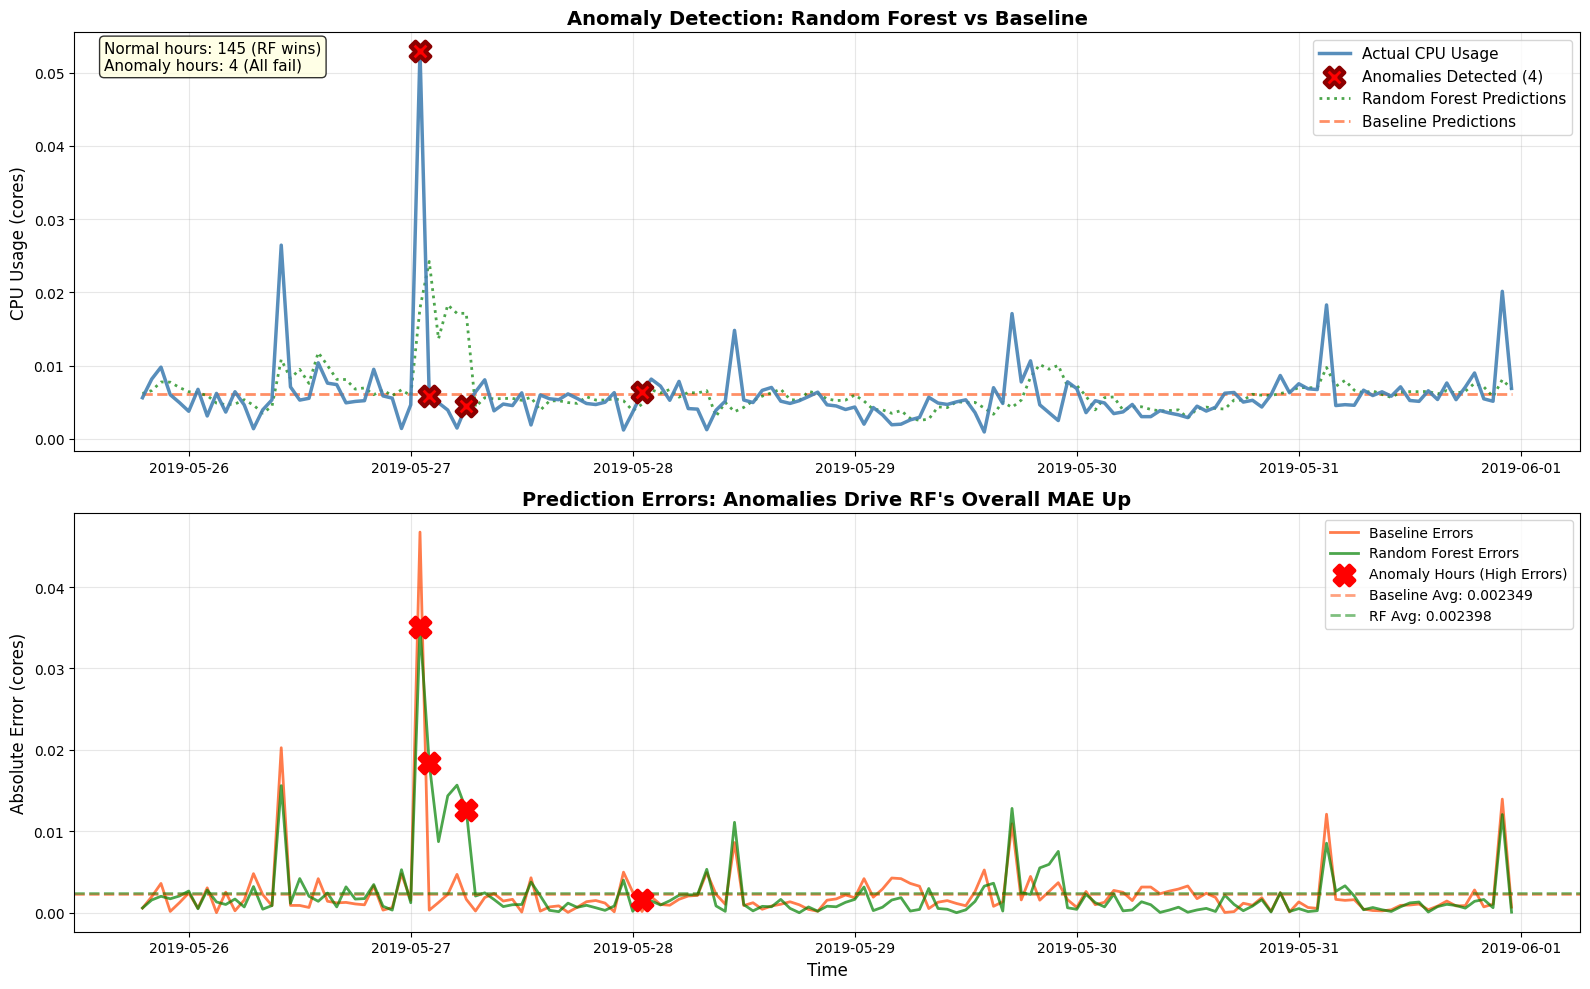

In [186]:
# ============================================================
# VISUALIZATION 1: ANOMALIES HIGHLIGHTED
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Top plot: Full time series with anomalies marked
axes[0].plot(test_rf['timestamp'], y_test, 
            label='Actual CPU Usage', linewidth=2.5, 
            color='steelblue', alpha=0.9, zorder=3)

# Highlight anomalies with red X markers
axes[0].scatter(test_rf['timestamp'].iloc[is_anomaly], 
               y_test.iloc[is_anomaly],
               color='red', s=200, marker='X', linewidths=3,
               label=f'Anomalies Detected ({is_anomaly.sum()})', 
               zorder=5, edgecolors='darkred')

# Show RF predictions
axes[0].plot(test_rf['timestamp'], rf_model_predictions,
            label='Random Forest Predictions', linewidth=2, 
            linestyle=':', color='green', alpha=0.7, zorder=2)

# Show baseline
axes[0].plot(test_rf['timestamp'], baseline_predictions[:len(test_rf)],
            label='Baseline Predictions', linewidth=2, 
            linestyle='--', color='orangered', alpha=0.6, zorder=1)

axes[0].set_title('Anomaly Detection: Random Forest vs Baseline', 
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('CPU Usage (cores)', fontsize=12)
axes[0].legend(fontsize=11, loc='upper right')
axes[0].grid(alpha=0.3)

# Add annotation box
textstr = f'Normal hours: {is_normal.sum()} (RF wins)\nAnomaly hours: {is_anomaly.sum()} (All fail)'
axes[0].text(0.02, 0.98, textstr, transform=axes[0].transAxes,
            fontsize=11, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

# Bottom plot: Prediction errors over time
baseline_errors = np.abs(y_test.values - baseline_predictions[:len(test_rf)])
rf_errors = np.abs(y_test.values - rf_model_predictions)

axes[1].plot(test_rf['timestamp'], baseline_errors,
            label='Baseline Errors', linewidth=2, 
            color='orangered', alpha=0.7)
axes[1].plot(test_rf['timestamp'], rf_errors,
            label='Random Forest Errors', linewidth=2, 
            color='green', alpha=0.7)

# Mark anomaly locations
axes[1].scatter(test_rf['timestamp'].iloc[is_anomaly],
               rf_errors[is_anomaly],
               color='red', s=200, marker='X', linewidths=3,
               label='Anomaly Hours (High Errors)', zorder=5)

axes[1].axhline(baseline_mae, color='orangered', 
               linestyle='--', linewidth=2, alpha=0.5,
               label=f'Baseline Avg: {baseline_mae:.6f}')
axes[1].axhline(rf_model_mae, color='green', 
               linestyle='--', linewidth=2, alpha=0.5,
               label=f'RF Avg: {rf_model_mae:.6f}')

axes[1].set_title('Prediction Errors: Anomalies Drive RF\'s Overall MAE Up', 
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel('Time', fontsize=12)
axes[1].set_ylabel('Absolute Error (cores)', fontsize=12)
axes[1].legend(fontsize=10, loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('anomaly_detection_analysis.png', dpi=300, bbox_inches='tight')
plt.show()


In [188]:
# ============================================================
# INVESTIGATE: Why Were These Hours Flagged?
# ============================================================

print("="*60)
print("ANOMALY INVESTIGATION")
print("="*60)

# Get the anomalous hours
anomaly_data = test_rf.iloc[is_anomaly].copy()
anomaly_features = X_test[is_anomaly]

print(f"\n🚨 {is_anomaly.sum()} Anomalies detected:")
print("\nTimestamp | CPU Usage | Reason it might be flagged")
print("-" * 80)

for idx, (timestamp, cpu) in enumerate(zip(anomaly_data['timestamp'], 
                                            anomaly_data['cpu_usage'])):
    features = anomaly_features.iloc[idx]
    
    print(f"\n{timestamp}")
    print(f"  CPU: {cpu:.6f}")
    print(f"  Features:")
    print(f"    hour: {features['hour']}")
    print(f"    day_of_week: {features['day_of_week']}")
    print(f"    lag_1: {features['lag_1']:.6f}")
    print(f"    lag_24: {features['lag_24']:.6f}")
    print(f"    rolling_mean_6: {features['rolling_mean_6']:.6f}")
    print(f"    rolling_std_6: {features['rolling_std_6']:.6f}")
    
    # Check what's unusual
    if cpu > 0.020:
        print(f"  → High CPU value! (>0.020)")
    if features['rolling_std_6'] > 0.005:
        print(f"  → High volatility! (rolling_std > 0.005)")
    if abs(cpu - features['lag_1']) > 0.010:
        print(f"  → Big change from last hour! (Δ = {abs(cpu - features['lag_1']):.6f})")
    if abs(cpu - features['lag_24']) > 0.015:
        print(f"  → Very different from same time yesterday!")

# Compare to normal hours
print("\n" + "="*60)
print("NORMAL HOURS (for comparison)")
print("="*60)
normal_features = X_test[is_normal]
print(f"\nTypical feature ranges in normal hours:")
print(f"  CPU range: {y_test[is_normal].min():.6f} - {y_test[is_normal].max():.6f}")
print(f"  rolling_std_6 range: {normal_features['rolling_std_6'].min():.6f} - {normal_features['rolling_std_6'].max():.6f}")
print(f"  Typical lag_1 vs current change: {np.mean(np.abs(y_test[is_normal].values - normal_features['lag_1'].values)):.6f}")


ANOMALY INVESTIGATION

🚨 4 Anomalies detected:

Timestamp | CPU Usage | Reason it might be flagged
--------------------------------------------------------------------------------

2019-05-27 01:00:00
  CPU: 0.052931
  Features:
    hour: 1.0
    day_of_week: 0.0
    lag_1: 0.004638
    lag_24: 0.006749
    rolling_mean_6: 0.013309
    rolling_std_6: 0.019583
  → High CPU value! (>0.020)
  → High volatility! (rolling_std > 0.005)
  → Big change from last hour! (Δ = 0.048293)
  → Very different from same time yesterday!

2019-05-27 02:00:00
  CPU: 0.005859
  Features:
    hour: 2.0
    day_of_week: 0.0
    lag_1: 0.052931
    lag_24: 0.003113
    rolling_mean_6: 0.012704
    rolling_std_6: 0.019779
  → High volatility! (rolling_std > 0.005)
  → Big change from last hour! (Δ = 0.047072)

2019-05-27 06:00:00
  CPU: 0.004518
  Features:
    hour: 6.0
    day_of_week: 0.0
    lag_1: 0.001462
    lag_24: 0.004619
    rolling_mean_6: 0.012268
    rolling_std_6: 0.019976
  → High volatility! (